## Prédire la taille du panier (rayon boulangerie)

Chargement des données nettoyées produites par `notebook.ipynb`.

In [ ]:
import pandas as pd

df = pd.read_csv('df_clean.csv')

In [12]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Préparation des données (Calcul de la taille du panier + Historique)
cart_sizes = df.groupby('order_id')['product_name'].count().reset_index()
cart_sizes.columns = ['order_id', 'cart_size']
cart_sizes = cart_sizes[cart_sizes['cart_size'] < 50] # On enlève les paniers géants

user_avg_cart = df.groupby(['user_id', 'order_id'])['product_name'].count().reset_index()
user_avg_cart = user_avg_cart.groupby('user_id')['product_name'].mean().reset_index()
user_avg_cart.columns = ['user_id', 'user_avg_size']

# Fusion pour le modèle Bakery
df_bakery = df[df['department'] == 'bakery'].copy()
df_model = pd.merge(df_bakery, cart_sizes, on='order_id')
df_model = pd.merge(df_model, user_avg_cart, on='user_id')

# 2. Variables (Features)
features = ['order_dow', 'order_hour_of_day', 'days_since_prior_order', 'user_avg_size']
X = df_model[features].fillna(0)
y = df_model['cart_size']

# Échantillonnage pour la rapidité
X = X.sample(min(len(X), 100000), random_state=42)
y = y.loc[X.index]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Modèle Random Forest
model_rf = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
model_rf.fit(X_train, y_train)

# 4. Affichage des scores
y_pred = model_rf.predict(X_test)

print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f}")
print(f"R2  : {r2_score(y_test, y_pred):.4f}")

MAE : 4.25
R2  : 0.5803


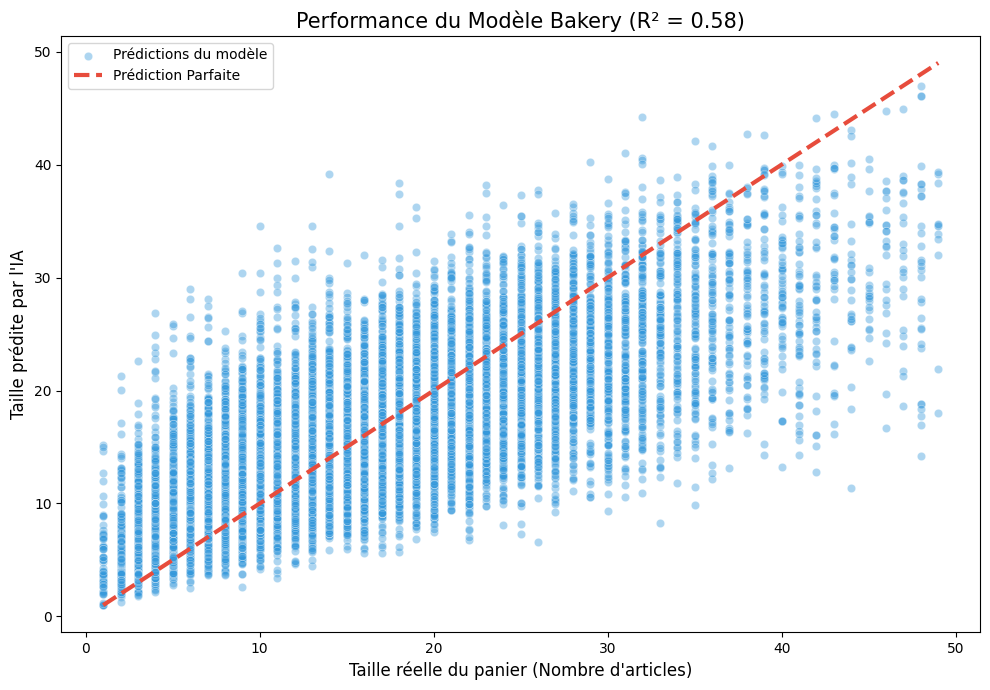

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# On crée un graphique plus visuel
plt.figure(figsize=(10, 7))

# On trace les points (en bleu transparent pour voir la densité)
sns.scatterplot(x=y_test, y=y_pred, alpha=0.4, color="#3498db", label='Prédictions du modèle')

# On trace la ligne de perfection (en rouge)
# Si tous les points étaient sur cette ligne, le score serait de 1.0
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 
         color='#e74c3c', lw=3, linestyle='--', label='Prédiction Parfaite')

# Design et labels
plt.title(f'Performance du Modèle Bakery (R² = {r2_score(y_test, y_pred):.2f})', fontsize=15)
plt.xlabel('Taille réelle du panier (Nombre d\'articles)', fontsize=12)
plt.ylabel('Taille prédite par l\'IA', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()